# Линейная регрессия: аналитическое решение (OLS), регуляризация (Ridge/Lasso/ElasticNet) и классификация

## О проекте
В данном проекте исследуются возможности и ограничения линейных моделей на датасете **Travel Insurance**:
1. **Задача регрессии:** Прогнозирование суммы чистых продаж (`Net Sales`) с помощью классического OLS и моделей с регуляризацией ($L_1$, $L_2$, ElasticNet).
2. **Задача классификации:** Прогнозирование факта страховой выплаты (`Claim`) через линейную регрессию с округлением в условиях сильного дисбаланса классов (98.5% / 1.5%).
3. **Реализация с нуля (NumPy):** 
   - Аналитическое решение обычного МНК (OLS) с использованием `np.linalg.lstsq`.
   - Аналитическое решение $L_2$-регуляризации (Ridge) для устранения проблемы мультиколлинеарности и вырожденности матрицы $X^T X$.
   - Сравнение с реализацией `LinearRegression` из `scikit-learn`.
4. **Метрики качества:** Анализ применимости MSE, MAE, MAPE, $R^2$ в регрессии, а также ROC-AUC, Balanced Accuracy, Precision, Recall и $F_\beta$-score (при $\beta=2$) при сильном дисбалансе классов.

---
### Описание признаков
* `Agency` — название страхового агентства
* `Agency Type` — тип страхового агентства
* `Distribution Channel` — канал продвижения
* `Product Name` — название страхового продукта
* `Duration` — длительность поездки (дней)
* `Destination` — направление поездки
* `Net Sales` — сумма продаж (целевая переменная для регрессии)
* `Commision (in value)` — комиссия агентства
* `Gender` — пол застрахованного
* `Age` — возраст застрахованного
* `Claim` — потребовалась ли страховая выплата (целевая переменная для классификации: «да» — 1, «нет» — 0)


## 1. Исследовательский анализ данных (EDA) и предобработка


In [106]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
from sklearn.linear_model import LinearRegression

In [107]:
df = pd.read_csv("travel insurance.csv")

df.head()

,Agency,Agency Type,Distribution Channel,Product Name,Claim,Duration,Destination,Net Sales,Commision (in value),Gender,Age
0,CBH,Travel Agency,Offline,Comprehensive Plan,No,186,MALAYSIA,-29.0,9.57,F,81
1,CBH,Travel Agency,Offline,Comprehensive Plan,No,186,MALAYSIA,-29.0,9.57,F,71
2,CWT,Travel Agency,Online,Rental Vehicle Excess Insurance,No,65,AUSTRALIA,-49.5,29.70,NaN,32
3,CWT,Travel Agency,Online,Rental Vehicle Excess Insurance,No,60,AUSTRALIA,-39.6,23.76,NaN,32
4,CWT,Travel Agency,Online,Rental Vehicle Excess Insurance,No,79,ITALY,-19.8,11.88,NaN,41


In [108]:
print(f"Размер выборки {df.shape}")

Размер выборки (63326, 11)


In [109]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 63326 entries, 0 to 63325
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Agency                63326 non-null  object 
 1   Agency Type           63326 non-null  object 
 2   Distribution Channel  63326 non-null  object 
 3   Product Name          63326 non-null  object 
 4   Claim                 63326 non-null  object 
 5   Duration              63326 non-null  int64  
 6   Destination           63326 non-null  object 
 7   Net Sales             63326 non-null  float64
 8   Commision (in value)  63326 non-null  float64
 9   Gender                18219 non-null  object 
 10  Age                   63326 non-null  int64  
dtypes: float64(2), int64(2), object(7)
memory usage: 5.3+ MB


In [110]:
df.isnull().sum()

Agency                      0
Agency Type                 0
Distribution Channel        0
Product Name                0
Claim                       0
Duration                    0
Destination                 0
Net Sales                   0
Commision (in value)        0
Gender                  45107
Age                         0
dtype: int64

<Axes: >

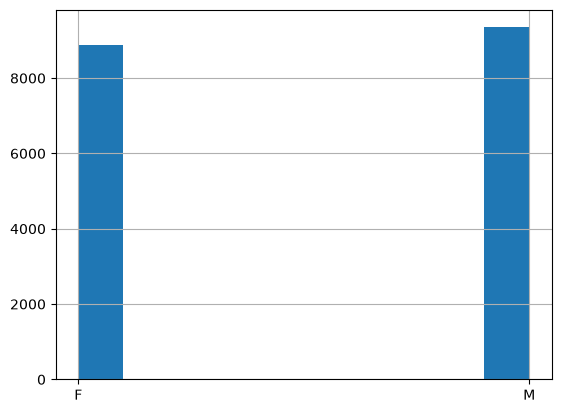

In [111]:
df.Gender.hist()

<Axes: >

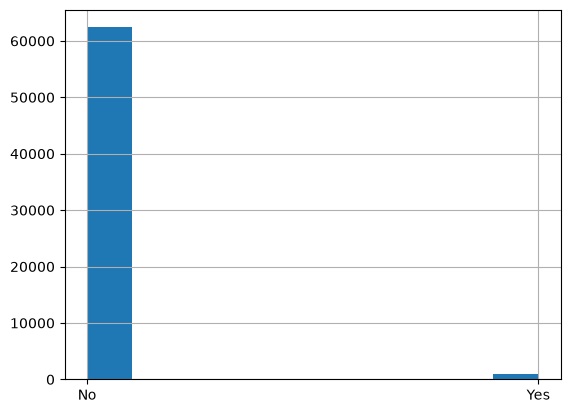

In [112]:
df.Claim.hist()

array([[<Axes: title={'center': 'Duration'}>,
        <Axes: title={'center': 'Net Sales'}>],
       [<Axes: title={'center': 'Commision (in value)'}>,
        <Axes: title={'center': 'Age'}>]], dtype=object)

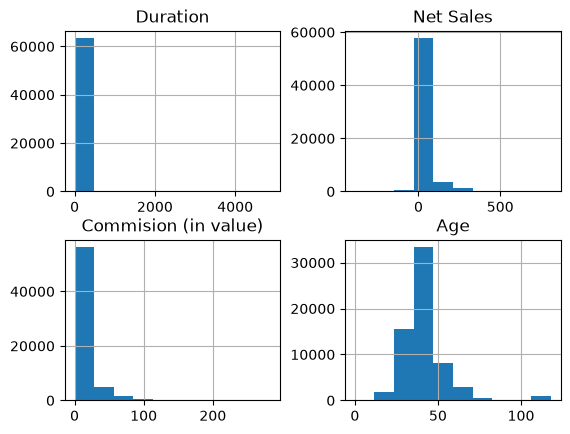

In [113]:
df.hist()

([<matplotlib.axis.XTick at 0x179ae746c10>,
 [Text(0, 0, '0'),
  Text(500, 0, '500'),
  Text(1000, 0, '1000'),
  Text(1500, 0, '1500'),
  Text(2000, 0, '2000'),
  Text(2500, 0, '2500'),
  Text(3000, 0, '3000'),
  Text(3500, 0, '3500'),
  Text(4000, 0, '4000'),
  Text(4500, 0, '4500')])

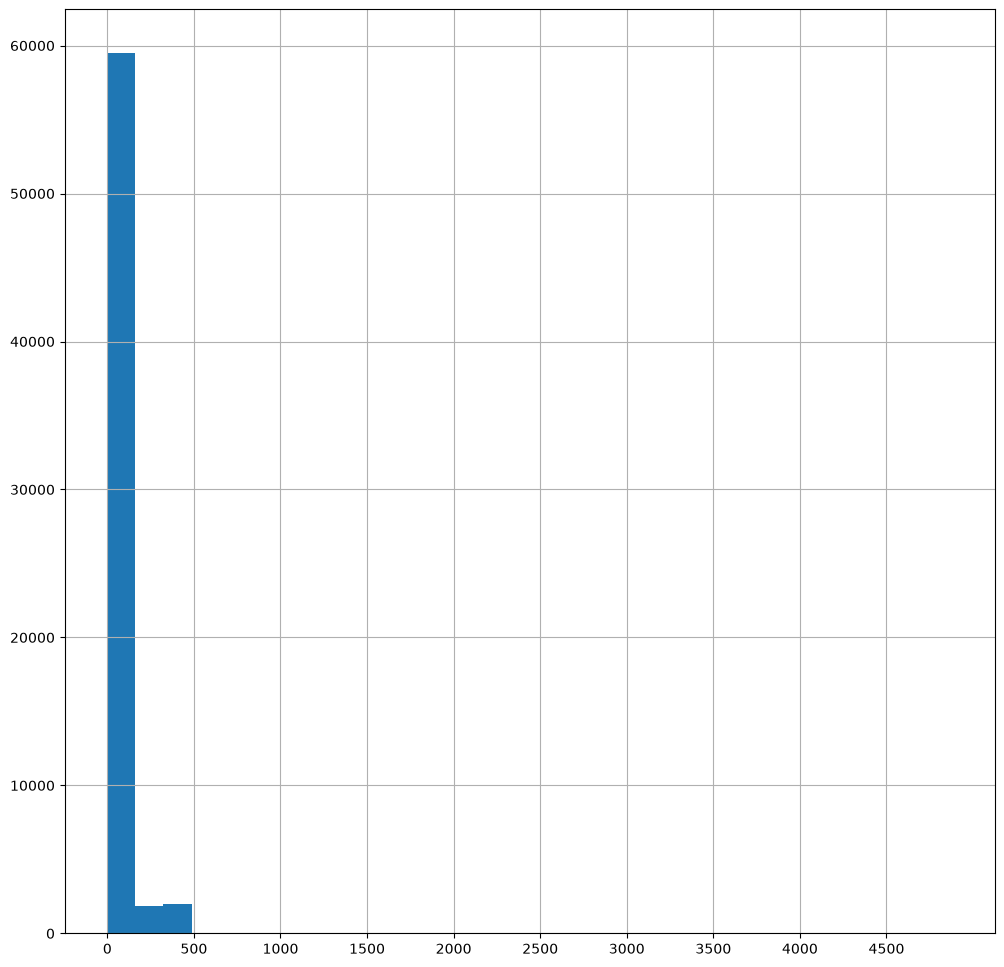

In [114]:
df.Duration.hist(bins=30, figsize=(12,12))
plt.xticks(np.arange(0, 5000, 500))

Я заметил тут очень большой выброс, поэтому думаю будет правильно ограничить значения

In [115]:
df = df[(df['Duration'] >= 0) & (df["Duration"] <= 500)]

<Axes: >

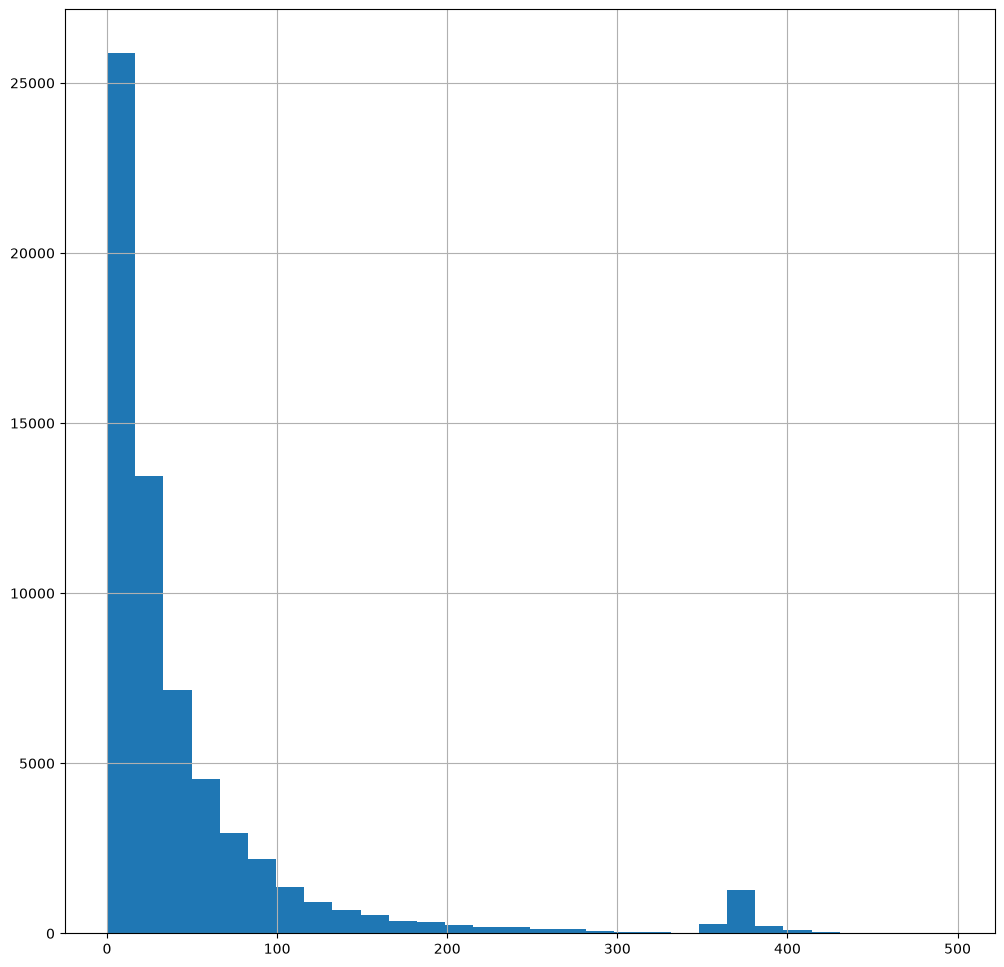

In [116]:
df.Duration.hist(bins=30, figsize=(12,12))

Распределение скошено вправо, так что думаю что стоит прологарифмировать признак, чтобы линейная регрессия работала стабильнее

<Axes: >

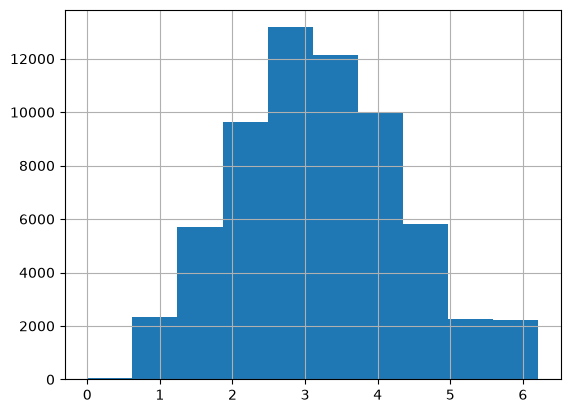

In [117]:
df['Duration'] = np.log1p(df['Duration'])
df['Duration'].hist()

Другое дело :)

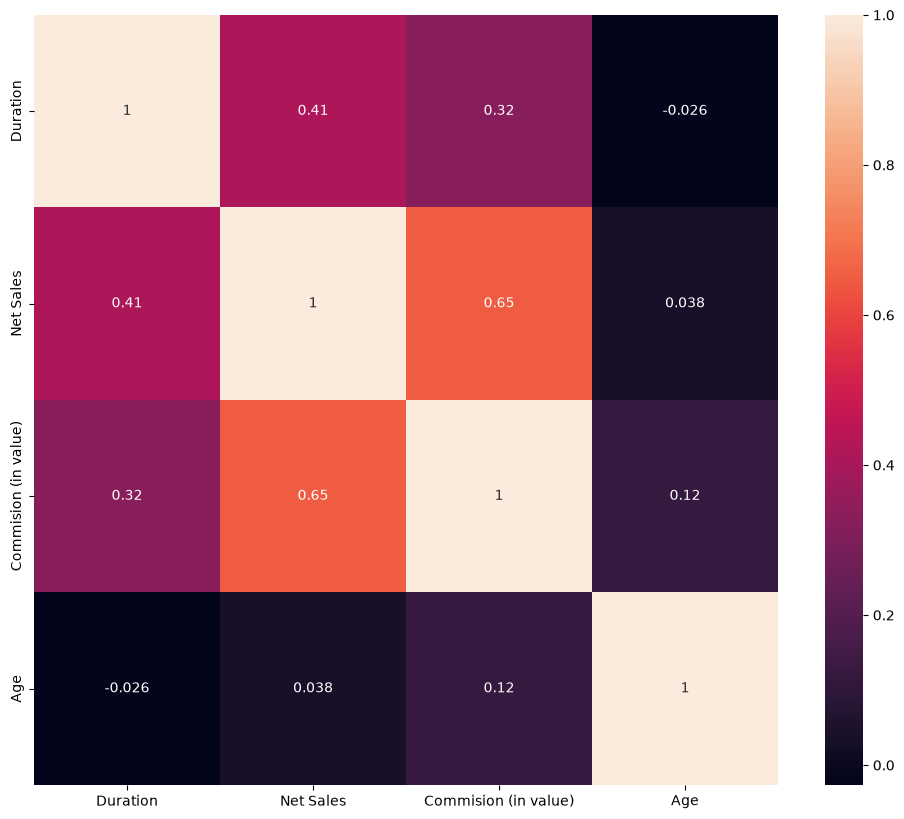

In [118]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(numeric_only=True), annot=True);

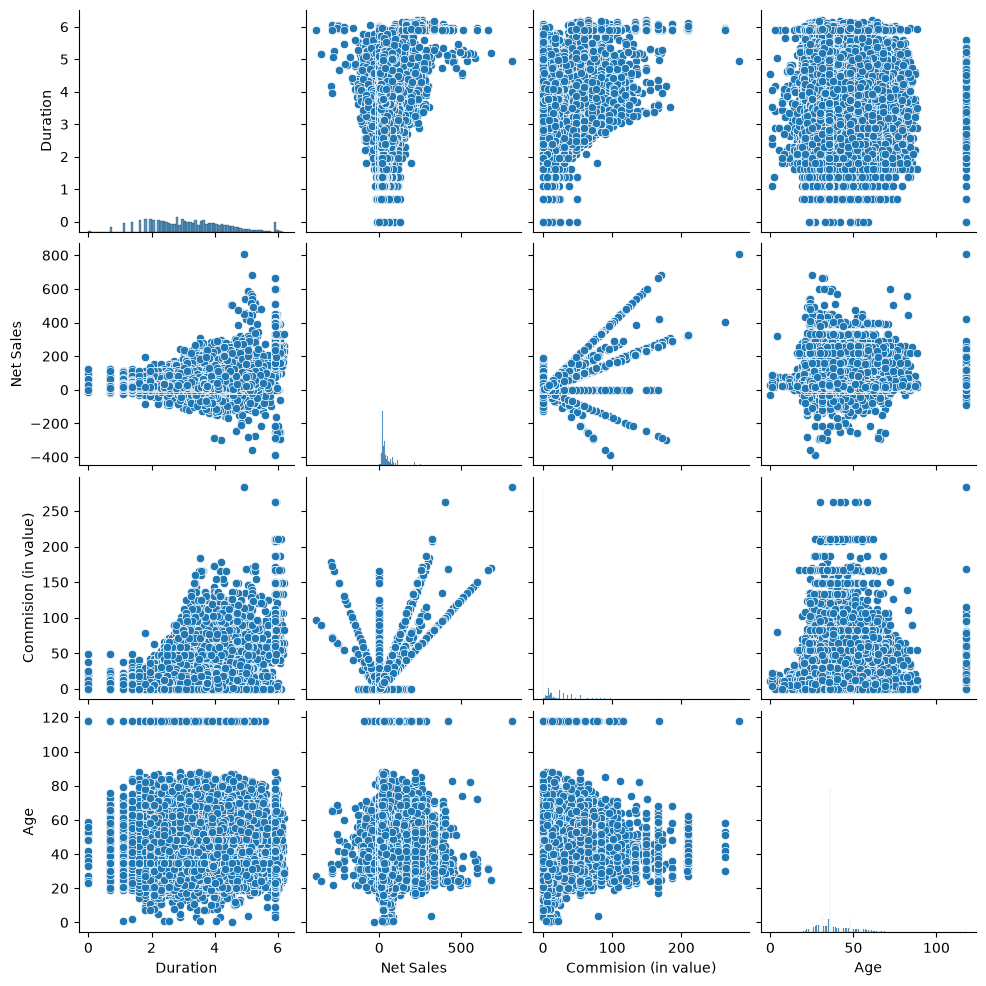

In [119]:
sns.pairplot(df)

Опа, даталик на Comission :)

Я подумал, у нас очень много пропусков в "Gender", я хотел удалть эти строки, но там 40к+ строк с пропусками, и очень много информации я потеряю, так что думаю стоит заменить пропуски значением "Unknown". На практике иногда это даже помогало находить скрытые закономерности. Дай бог все хорошо будет:)

In [120]:
df['Gender'] = df['Gender'].fillna("Unknown")

<Axes: >

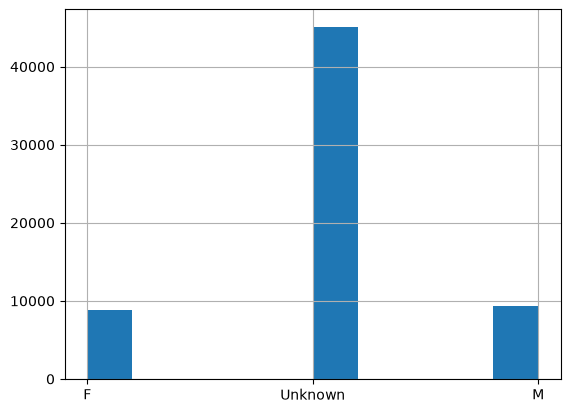

In [121]:
df.Gender.hist()

In [122]:
df.Destination.value_counts()

Destination
SINGAPORE                 13234
MALAYSIA                   5929
THAILAND                   5894
CHINA                      4795
AUSTRALIA                  3694
                          ...  
GUATEMALA                     1
TIBET                         1
SENEGAL                       1
REPUBLIC OF MONTENEGRO        1
BOSNIA AND HERZEGOVINA        1
Name: count, Length: 149, dtype: int64

Увидел что тут есть очень много нишевых айтемов, так что думаю стоит сделать условное разграничение, чтобы при OHE(охае) было не так много столбцов

In [123]:
country_counts = df['Destination'].value_counts()
rare_countries = country_counts[country_counts < 100].index
df['Destination'] = df['Destination'].apply(lambda x: 'Other' if x in rare_countries else x)

### Регрессионное предсказание суммы продаж



#### **Ответ:**
По пэирплоту я нашел линейную зависимость между "Net Sles" и "Comission" и по логике вещей, "Claim" тоже будет даталиком, потому что если все таки страхование было (1) то это значит сумма продаж повышалась, у них существует такая же линейная зависимость. А что касается вопроса про почему нужно удалять даталики, я думаю их надо убирать из датасета, потому что они у нас уже есть данные из будущего и соответсвенна модель будет подглядывать в эти данные, и соответственно будет переобучаться на них, на валидации метрики будут высокие, а на реальном тесте модель будет не ликвидна

In [124]:
y = df['Net Sales']
X = df.drop(columns=['Net Sales', 'Commision (in value)', 'Claim'])

In [125]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 63297 entries, 0 to 63325
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Agency                63297 non-null  object 
 1   Agency Type           63297 non-null  object 
 2   Distribution Channel  63297 non-null  object 
 3   Product Name          63297 non-null  object 
 4   Claim                 63297 non-null  object 
 5   Duration              63297 non-null  float64
 6   Destination           63297 non-null  object 
 7   Net Sales             63297 non-null  float64
 8   Commision (in value)  63297 non-null  float64
 9   Gender                63297 non-null  object 
 10  Age                   63297 non-null  int64  
dtypes: float64(3), int64(1), object(7)
memory usage: 5.8+ MB


In [127]:
cat_f_mask = (X_train.dtypes == "object").values
cat_cols = X_train.columns[cat_f_mask].tolist()
num_cols = X_train.columns[~cat_f_mask].tolist()

In [128]:
encoder = OneHotEncoder(drop="first", sparse_output=False) # охае

X_train_cat = encoder.fit_transform(X_train[cat_cols])
X_test_cat = encoder.transform(X_test[cat_cols]) 

In [129]:
mmscaler = MinMaxScaler()

X_train_num = mmscaler.fit_transform(X_train[num_cols])
X_test_num = mmscaler.transform(X_test[num_cols]) 

In [130]:
X_train_conc = np.hstack((X_train_num, X_train_cat))
X_test_conc = np.hstack((X_test_num, X_test_cat))

In [131]:
print(f"X_train : {X_train_conc.shape}")
print(f"X_test : {X_test_conc.shape}")

X_train : (50637, 85)
X_test : (12660, 85)


In [132]:
linreg_model = LinearRegression()
linreg_model.fit(X_train_conc, y_train)

y_pred = linreg_model.predict(X_test_conc)

In [133]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, mean_squared_error, root_mean_squared_error, r2_score, median_absolute_error, explained_variance_score 
# Больщая часть метрик для экспериментов :) (В конце ноутбука)

def print_metrics(y_true, y_pred):
    print(f"MAE: {mean_absolute_error(y_true, y_pred)}")
    print(f"MSE: {mean_squared_error(y_true, y_pred)}")
    print(f"RMSE: {root_mean_squared_error(y_true, y_pred)}")
    print(f"MAPE: {mean_absolute_percentage_error(y_true, y_pred)}")
    print(f"R2: {r2_score(y_true, y_pred)}")
    print(f"MedAE: {median_absolute_error(y_true, y_pred)}")
    print(f"EVS: {explained_variance_score(y_true, y_pred)}")

In [134]:
print_metrics(y_test, y_pred)

MAE: 17.735033415457124
MSE: 873.8432983366985
RMSE: 29.5608406229711
MAPE: 6235676351574134.0
R2: 0.6343673455139821
MedAE: 10.802257359781905
EVS: 0.6343795050230793


#### **Ответ:**
- **MAE** - показывает что в среднем модель ошибается на 17.7 единиц целевой (Будем думать что это доллары)
- **MSE** - показывает что в среднем модель ошибьвается на 873.8 единиц^2 (долларов^2)
- **RMSE** - показывает что в среднем модель ошибается на 29.5 единиц (долларов (Она больше MAE потому что есть крупные промахи))
- **MAPE** - показывает на сколько процентов ошибается модель относительно реальной цены (Судя по всему на этом датасете она неликвидна)))))))))
- **R2** - объясняет долю разброса целевой, которую смогла объяснить модель (у нас модель объяснила 63%, 37% - не смогла объяснить(шум))
- **MedAE** - показывает медиану всех абсолютных ошибок (на половине модель ошиблась меньше 10.8, а на другой больше)
- **EVS** - измеряет корреляцию между pred и real, игнорируя bias (в моем случае она +- = R2, это означает что у моделт нету bias)

## 3. Классификация с помощью линейных моделей (прогнозирование Claim)

Решение задачи бинарной классификации с помощью линейной регрессии путем округления непрерывного предсказания до ближайшего целого {0, 1}.


In [135]:
df['Bin_Claim'] = np.where(df['Claim'] == 'Yes', 1, 0)
y_class = df['Bin_Claim']
X_class = df.drop(columns=['Net Sales', 'Commision (in value)', 'Claim', 'Bin_Claim'])

In [136]:
X_train_cl, X_test_cl, y_train_cl, y_test_cl = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

In [137]:
train_data = pd.DataFrame(X_train_cl)
train_data['target'] = y_train_cl

df_majority = train_data[train_data['target'] == 0]
df_minority = train_data[train_data['target'] == 1]

df_majority_downsampled = df_majority.sample(n=len(df_minority), random_state=42)

train_downsampled = pd.concat([df_majority_downsampled, df_minority])

train_downsampled = train_downsampled.sample(frac=1, random_state=42).reset_index(drop=True)

X_train_cl = train_downsampled.drop(columns=['target'])
y_train_cl = train_downsampled['target'].values

In [138]:
cat_f_mask_cl = (X_train_cl.dtypes == "object").values

cat_cols_cl = [
    'Agency', 'Agency Type', 'Distribution Channel',
    'Product Name', 'Destination', 'Gender'
]

num_cols_cl = ['Duration', 'Age']

In [139]:
X_train_cl[cat_cols_cl] = X_train_cl[cat_cols_cl].fillna("Unknown").astype(str)
X_test_cl[cat_cols_cl] = X_test_cl[cat_cols_cl].fillna("Unknown").astype(str)

encoder_cl = OneHotEncoder(drop="first", sparse_output=False, handle_unknown='ignore')

X_train_cl_cat = encoder_cl.fit_transform(X_train_cl[cat_cols_cl])
X_test_cl_cat = encoder_cl.transform(X_test_cl[cat_cols_cl])

c:\Users\admin\anaconda3\Lib\site-packages\sklearn\preprocessing\_encoders.py:246: UserWarning: Found unknown categories in columns [0, 4] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


In [140]:
scaler_cl = MinMaxScaler()

X_train_cl_num = scaler_cl.fit_transform(X_train_cl[num_cols_cl])
X_test_cl_num = scaler_cl.transform(X_test_cl[num_cols_cl])

In [141]:
X_train_cl_conc = np.hstack((X_train_cl_num, X_train_cl_cat))
X_test_cl_conc = np.hstack((X_test_cl_num, X_test_cl_cat))

In [142]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, fbeta_score, roc_auc_score, average_precision_score

def print_classification_metrics(y_true, y_pred, y_prob = None):
    print(f"Accuracy: {accuracy_score(y_true, y_pred)}")
    print(f"Precision: {precision_score(y_true, y_pred, zero_division=0)}")
    print(f"Recall: {recall_score(y_true, y_pred)}")
    print(f"F1: {f1_score(y_true, y_pred)}")
    print(f"F-beta: {fbeta_score(y_true, y_pred, beta=1.0)}")
    print(f"Balanced Accuracy: {balanced_accuracy_score(y_true, y_pred)}")
    
    if y_prob is not None:
        print(f"ROC-AUC: {roc_auc_score(y_true, y_prob)}")
        print(f"AP: {average_precision_score(y_true, y_prob)}")
    

### Аналитическое решение: МНК (OLS) и L2-регуляризация (Ridge) с нуля на NumPy


In [143]:
ones_column = np.ones((X_train_cl_conc.shape[0], 1))
X_train_bias = np.hstack([ones_column, X_train_cl_conc])

y_train_arr = np.asarray(y_train_cl)

XTX = X_train_bias.T @ X_train_bias


w_ols = np.linalg.lstsq(X_train_bias, y_train_arr, rcond=None)[0]


lam = 1.0 
I = np.eye(X_train_bias.shape[1])
I[0, 0] = 0.0

w_l2 = np.linalg.inv(XTX + lam * I) @ X_train_bias.T @ y_train_arr

print("Веса OLS, размер:", w_ols.shape)
print("Веса L2, размер:", w_l2.shape)

Веса OLS, размер: (82,)
Веса L2, размер: (82,)


In [144]:
ones_test_cl = np.ones((X_test_cl_conc.shape[0], 1))
X_test_bias = np.hstack([ones_test_cl, X_test_cl_conc])


y_pred_ols_cont = X_test_bias @ w_ols 
y_pred_l2_cont = X_test_bias @ w_l2

y_prob_ols = np.clip(y_pred_ols_cont, 0, 1)
y_prob_l2 = np.clip(y_pred_l2_cont, 0, 1)

y_pred_ols_class = np.round(y_pred_ols_cont)
y_pred_l2_class = np.round(y_pred_l2_cont)

y_pred_ols_class = np.clip(y_pred_ols_class, 0, 1)
y_pred_l2_class = np.clip(y_pred_l2_class, 0, 1)

In [145]:
print_classification_metrics(y_test_cl, y_pred_ols_class, y_prob_ols)

Accuracy: 0.79913112164297
Precision: 0.05078274150439099
Recall: 0.7
F1: 0.09469562121751512
F-beta: 0.09469562121751512
Balanced Accuracy: 0.7503207698476343
ROC-AUC: 0.8046536951842316
AP: 0.055782087854146005


In [146]:
print_classification_metrics(y_test_cl, y_pred_l2_class, y_prob_l2)

Accuracy: 0.8032385466034755
Precision: 0.05181145305804441
Recall: 0.7
F1: 0.0964816829887559
F-beta: 0.0964816829887559
Balanced Accuracy: 0.7524057738572574
ROC-AUC: 0.8090151099480859
AP: 0.06117314300599436


### Сравнение с LinearRegression из scikit-learn


In [147]:
sk_model = LinearRegression()
sk_model.fit(X_train_cl_conc, y_train_cl)

y_pred_sk_cont = sk_model.predict(X_test_cl_conc)

y_pred_sk_class = np.round(y_pred_sk_cont)
y_pred_sk_class = np.clip(y_pred_sk_class, 0, 1)

y_prob_sk = np.clip(y_pred_sk_cont, 0, 1)

In [148]:
print_classification_metrics(y_test_cl, y_pred_sk_class, y_prob_sk)

Accuracy: 0.79913112164297
Precision: 0.05078274150439099
Recall: 0.7
F1: 0.09469562121751512
F-beta: 0.09469562121751512
Balanced Accuracy: 0.7503207698476343
ROC-AUC: 0.8048778120119866
AP: 0.05610954117490014


## 4. Итоговые выводы

1. **Предобработка данных:**
   - Из признака `Duration` удалены некорректные отрицательные значения и экстремальные выбросы (> 500 дней), после чего применено логарифмирование `np.log1p` для нормализации скошенного распределения.
   - В признаке `Gender` более 70% пропусков заполнены категорией `'Unknown'`, что позволило сохранить данные и выделить факт отсутствия пола в отдельный информативный признак.
   - В признаке `Destination` редкие направления (< 100 записей) объединены в категорию `'Other'`, чтобы уменьшить размерность OHE и снизить мультиколлинеарность.
   - Категориальные признаки закодированы через `OneHotEncoder(drop='first')`, а числовые нормализованы с помощью `MinMaxScaler`.

2. **Оценка моделей:**
   - **Регрессия (Net Sales):** Линейная модель объясняет около 63.4% дисперсии ($R^2 \approx 0.634$) со средней абсолютной ошибкой MAE $\approx 17.7$. Регуляризация (Ridge/LassoCV) дает схожий результат, так как объем данных достаточен для стабильной оценки весов. Метрика MAPE на данном датасете неликвидна из-за наличия околонулевых и отрицательных значений целевой переменной.
   - **Классификация (Claim):** Использование аналитического МНК (или псевдообратной матрицы / L2) показало хорошее качество ранжирования (ROC-AUC $\approx 0.81$ и Balanced Accuracy $\approx 75\%$). Из-за сильного дисбаланса классов модель имеет низкую точность (Precision $\approx 5\%$), однако улавливает 70% реальных выплат (Recall $\approx 70\%$), что в рамках страховой задачи является приоритетом.


#### **Ответ:** (для LinearRegression из sklearn)
- Accuracy - модель верно дала ответ для 79.9% объектов
- Precission - из всех объектов, которые модель назвала 1, реальными 1 оказалось всего 5% :)))
- Recall - модель поймала 70% от всех реальных 1
- F1 - баланс между Precission и Recall = 9%
- F-beta - в моем случае равен F1, потому что я не настроил параметр beta (а точнее он у меня =1)
- Balanced Accuracy - средняя точность по классам 75%
- ROC-AUC - 80% - вероятнось того, что модель отличит рандомную 1 от случайного 0
- AP - средняя точность на PR-кривой =5.6%

In [149]:
# Т.к. у нас задача, где у нас важна полнота, хочу привести пример метрики F-beta при параметре beta=2 => Recall важнее Precision

fbeta_score(y_test_cl, y_pred_sk_class, beta=2)

0.19680378810298904

Теперь у нас f-beta не 9% а 19.6%  выросло прилично!

1. Метрики по мимо MSE показывают,насколько эффективно мы находим целевыхъ клиентов
2. Я не знаю как правильно сформулировать, так что объясню на нашем примере: У нас есть наша модель, и из за жесткого дисбаланнса классов модель тупо всем будет тыкать 0, но Accuracy будет высокой, потому что по сути мы угадали класс условно для 80% "0", но из за этого мы пропустим почти все выплаты, метрика Precision показывает это (у нас 5%)
3. В задаче прогнозирования выплат - пропущеная выплата обходится компании дороже чем ложная тревога. Поэтому думаю стоит максимизировать Recall

## 5. Сравнение методов регуляризации (Ridge, Lasso, ElasticNet)


In [150]:
from sklearn.linear_model import Ridge, RidgeCV, Lasso, LassoCV, ElasticNet, ElasticNetCV

In [151]:
print_metrics(y_test, y_pred)

MAE: 17.735033415457124
MSE: 873.8432983366985
RMSE: 29.5608406229711
MAPE: 6235676351574134.0
R2: 0.6343673455139821
MedAE: 10.802257359781905
EVS: 0.6343795050230793


In [152]:
ridge_model = Ridge()
ridge_model.fit(X_train_conc, y_train)

y_pred_ridge = ridge_model.predict(X_test_conc)

print_metrics(y_test, y_pred_ridge)

MAE: 17.7386502183319
MSE: 874.0297926637052
RMSE: 29.563994869836268
MAPE: 6237421318406260.0
R2: 0.6342893127408753
MedAE: 10.801895641839337
EVS: 0.6343008716799037


In [153]:
alphas_grid = np.logspace(-2, 3, 20)


ridge_cv_model = RidgeCV(alphas=alphas_grid, cv=5)
ridge_cv_model.fit(X_train_conc, y_train)

y_pred_ridge_cv = ridge_cv_model.predict(X_test_conc)

print(f"Лучший alpha: {ridge_cv_model.alpha_}")

print_metrics(y_test, y_pred_ridge_cv)

Лучший alpha: 0.37926901907322497
MAE: 17.73609878242054
MSE: 873.9021083395039
RMSE: 29.561835334422387
MAPE: 6236442691496843.0
R2: 0.6343427382903792
MedAE: 10.81075108306845
EVS: 0.6343546367450517


In [154]:
lasso_model = Lasso()
lasso_model.fit(X_train_conc, y_train)

y_pred_lasso = lasso_model.predict(X_test_conc)

print_metrics(y_test, y_pred_lasso)

MAE: 23.755387813677977
MSE: 1476.5797870365202
RMSE: 38.426290310626136
MAPE: 5585377774523170.0
R2: 0.3821709359993972
MedAE: 16.40583798999978
EVS: 0.3821888815537814


In [155]:
lasso_model_cv = LassoCV(alphas=alphas_grid, cv=5)
lasso_model_cv.fit(X_train_conc, y_train)

y_pred_lasso_cv = lasso_model_cv.predict(X_test_conc)

print(f"Лучший alpha: {lasso_model_cv.alpha_}")

print_metrics(y_test, y_pred_lasso_cv)

Лучший alpha: 0.01
MAE: 17.80600141578062
MSE: 876.2347841035448
RMSE: 29.601263218037584
MAPE: 6232095290276992.0
R2: 0.6333667023886507
MedAE: 10.950115551626894
EVS: 0.6333752779954904


In [156]:
elasticnet_model = ElasticNet()
elasticnet_model.fit(X_train_conc, y_train)

y_pred_elasticnet = elasticnet_model.predict(X_test_conc)

print_metrics(y_test, y_pred_elasticnet)

MAE: 28.303900916023988
MSE: 2138.9794735498403
RMSE: 46.24910240804507
MAPE: 5446473728429986.0
R2: 0.10501030986474247
MedAE: 19.29823031257206
EVS: 0.10507102553695247


In [157]:
elasticnet_cv_model = ElasticNetCV(alphas=alphas_grid, cv=5)
elasticnet_cv_model.fit(X_train_conc, y_train)

y_pred_elasticnet_cv_model = elasticnet_cv_model.predict(X_test_conc)

print(f"Лучший alpha: {elasticnet_cv_model.alpha_}")
print_metrics(y_test, y_pred_elasticnet_cv_model)

Лучший alpha: 0.01
MAE: 19.690190985478978
MSE: 1036.0370161332594
RMSE: 32.18752889137747
MAPE: 6139044719138872.0
R2: 0.5665024094415851
MedAE: 12.665915836346896
EVS: 0.5665035476250987
